In [3]:
import os
import torch
import torch.optim as optim
from torchvision import datasets, transforms
from torchvision.datasets import ImageFolder
import pandas as pd
from PIL import Image
import requests
import zipfile

import csv
from pathlib import Path
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torch.optim import AdamW, SGD
from torch.optim.lr_scheduler import CosineAnnealingLR
from tqdm import tqdm
from sklearn.metrics import precision_recall_fscore_support

import matplotlib.pyplot as plt

import ray
from ray import tune
from ray.tune.schedulers import ASHAScheduler
from ray.tune.search.optuna import OptunaSearch
from functools import partial


In [4]:
def download_tiny_imagenet():
    url = "http://cs231n.stanford.edu/tiny-imagenet-200.zip"
    data_dir = "/content/tiny-imagenet-200"
    if not os.path.exists(data_dir):
        print("Downloading Tiny ImageNet dataset...")
        response = requests.get(url, stream=True)
        with open("tiny-imagenet-200.zip", "wb") as f:
            for chunk in response.iter_content(chunk_size=8192):
                if chunk:
                    f.write(chunk)
        print("Extracting dataset...")
        with zipfile.ZipFile("tiny-imagenet-200.zip", "r") as zip_ref:
            zip_ref.extractall("/content")
        os.remove("tiny-imagenet-200.zip")
    return data_dir

# Define paths
data_dir = download_tiny_imagenet()
train_dir = os.path.join(data_dir, 'train')
val_dir = os.path.join(data_dir, 'val', 'images')
val_annotations = os.path.join(data_dir, 'val', 'val_annotations.txt')

print(f"Checking dataset directory: {data_dir}")
print(f"Directory exists: {os.path.exists(data_dir)}")
if os.path.exists(data_dir):
    print(f"Contents: {os.listdir(data_dir)}")
if not os.path.exists(train_dir):
    raise FileNotFoundError(f"Training directory not found: {train_dir}. Please verify the path.")
if not os.path.exists(val_dir):
    raise FileNotFoundError(f"Validation directory not found: {val_dir}. Please verify the path.")
if not os.path.exists(val_annotations):
    raise FileNotFoundError(f"Validation annotations not found: {val_annotations}. Please verify the path.")

# Check number of class folders
class_folders = [d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))]
print(f"Found {len(class_folders)} class folders in {train_dir}. Expected 200 for Tiny ImageNet.")


Checking dataset directory: /content/tiny-imagenet-200
Directory exists: True
Contents: ['test', 'train', 'words.txt', 'wnids.txt', 'val']
Found 200 class folders in /content/tiny-imagenet-200/train. Expected 200 for Tiny ImageNet.


In [5]:
import os, json, csv, collections, itertools
from pathlib import Path
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from torch.optim.lr_scheduler import MultiplicativeLR
from sklearn.metrics import precision_recall_fscore_support

ROOT_DIR = Path('/content/tiny-imagenet-200')
TRAIN_DIR = ROOT_DIR / 'train'
VAL_DIR   = ROOT_DIR / 'val'
TEST_DIR  = ROOT_DIR / 'test'

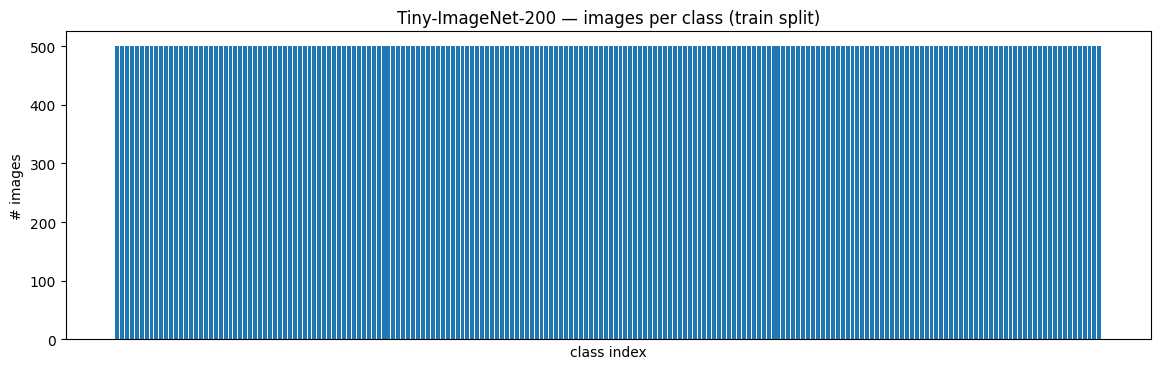

In [6]:
train_counts = {}
for cls_dir in TRAIN_DIR.iterdir():
    img_dir = cls_dir / 'images'
    n = len(list(img_dir.glob('*.JPEG')))
    train_counts[cls_dir.name] = n

codes, counts = zip(*sorted(train_counts.items(), key=lambda kv: kv[1], reverse=True))
plt.figure(figsize=(14,4))
plt.bar(range(len(codes)), counts)
plt.title('Tiny-ImageNet-200 — images per class (train split)')
plt.ylabel('# images'); plt.xlabel('class index')
plt.xticks([])
plt.show()


In [7]:
ACTIVATION_FN    = 'relu'

USE_BATCHNORM   = True
USE_DROPOUT     = False
DROP_P          = 0.1

OPTIMISER       = 'sgd'
LR              = 0.001
MOMENTUM        = 0.9
WEIGHT_DECAY    = 0.0001

EPOCHS          = 30

DEPTH            = 2
BASE_CHANNELS    = 64
Num_maxpool      = 2


USE_SCHEDULER   = False
LR_DECAY_COEFF = 0.1

BATCHSIZE       = 64
NUM_WORKERS     = 8

USE_EARLY_STOP  = True
PATIENCE        = 5


STEM_KERNEL_SIZE_1 = 3
STEM_KERNEL_SIZE_2 = 3
POOL_KERNEL_SIZE   = 3
HEAD_CONV_KERNEL_SIZE = 1
ADAPTIVE_POOL_OUTPUT_SIZE = 1
LAYER_CONFIGS      = [
    {'type': 'inception', 'out_ch': 64, 'kernel_size_1x1': 3, 'kernel_size_3x3': 5},
    {'type': 'conv', 'out_ch': 128, 'kernel_size': 7},
    {'type': 'inception', 'out_ch': 64, 'kernel_size_1x1': 1, 'kernel_size_3x3': 3}
]


n_cls=200,
p_drop=DROP_P,
depth=DEPTH,
base_channels=BASE_CHANNELS,
num_maxpool=Num_maxpool,
layer_configs=LAYER_CONFIGS,
pool_kernel_size=POOL_KERNEL_SIZE,
stem_kernel_size_1=STEM_KERNEL_SIZE_1,
stem_kernel_size_2=STEM_KERNEL_SIZE_2,
head_conv_kernel_size=HEAD_CONV_KERNEL_SIZE,
adaptive_pool_output_size=ADAPTIVE_POOL_OUTPUT_SIZE


In [8]:
wnids = [l.strip() for l in open(ROOT_DIR/'wnids.txt')]
syn2id = {c:i for i,c in enumerate(sorted(wnids))}

val_labels = {}
with open(VAL_DIR/'val_annotations.txt') as f:
    for fname, code, *_ in csv.reader(f, delimiter='\t'):
        val_labels[fname] = code

normalize = transforms.Normalize([0.485,0.456,0.406],
                                 [0.229,0.224,0.225])

train_tfms = transforms.Compose([
    transforms.RandomCrop(64, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), normalize,
])
eval_tfms  = transforms.Compose([transforms.ToTensor(), normalize])

class TinyImageNet(Dataset):
    def __init__(self, split, tfm):
        self.tfm = tfm
        if split=='train':
            self.samples = [
                (p, syn2id[p.parent.parent.name])
                for cls in TRAIN_DIR.iterdir()
                for p in (cls/'images').glob('*.JPEG')
            ]
        elif split=='val':
            imgdir = VAL_DIR/'images'
            self.samples = [(imgdir/fn, syn2id[val_labels[fn]]) for fn in val_labels]
        else:
            imgdir = TEST_DIR/'images'
            self.samples = [(p, -1) for p in imgdir.glob('*.JPEG')]

    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        path, y = self.samples[idx]
        img = Image.open(path).convert('RGB')
        return self.tfm(img), y

train_dl = DataLoader(TinyImageNet('train', train_tfms), BATCHSIZE,
                      shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
val_dl   = DataLoader(TinyImageNet('val',   eval_tfms),  BATCHSIZE,
                      shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
print(f"✓ dataset sizes — train {len(train_dl.dataset)}, val {len(val_dl.dataset)}")


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


✓ dataset sizes — train 100000, val 10000


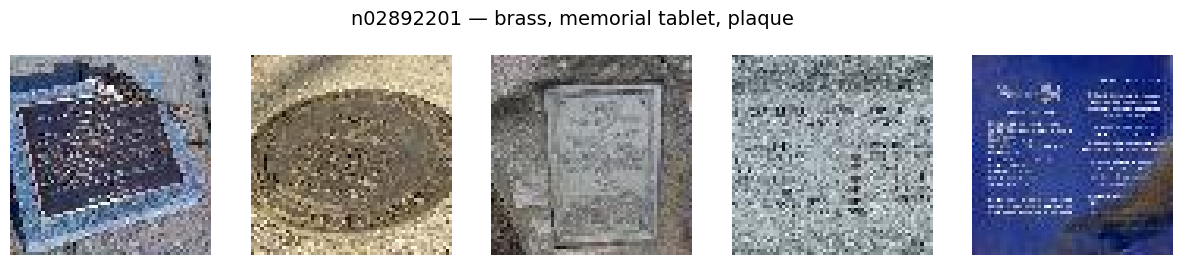

In [9]:
words = {code: label for code, label
         in (line.strip().split('\t') for line in open(ROOT_DIR/'words.txt'))}

import random, matplotlib.pyplot as plt
from PIL import Image

def show_samples(cls_code: str | None = None, n: int = 5):
    if cls_code is None:
        cls_code = random.choice(wnids)

    img_dir = TRAIN_DIR / cls_code / 'images'
    img_paths = random.sample(list(img_dir.glob('*.JPEG')), n)

    fig, axes = plt.subplots(1, n, figsize=(n*3, 3))
    for ax, p in zip(axes, img_paths):
        ax.imshow(Image.open(p))
        ax.axis('off')

    cls_name = words.get(cls_code, 'unknown')
    fig.suptitle(f'{cls_code} — {cls_name}', fontsize=14)
    plt.show()

show_samples('n02892201', n=5)


In [10]:
def get_activation_fn(name):
    name = name.lower()
    if name == 'relu':
        return nn.ReLU(inplace=True)
    elif name == 'leaky_relu':
        return nn.LeakyReLU(inplace=True)
    elif name == 'sigmoid':
        return nn.Sigmoid()
    elif name == 'tanh':
        return nn.Tanh()
    elif name == 'elu':
        return nn.ELU(inplace=True)
    elif name == 'softmax':
        return nn.Softmax(dim=1)
    else:
        raise ValueError(f"Unsupported activation function: {name}")

class InceptionResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, p_drop=DROP_P, kernel_size_1x1=1, kernel_size_3x3=3):
        super().__init__()
        half = out_ch // 2

        self.branch1 = nn.Sequential(
            nn.Conv2d(in_ch, half, kernel_size_1x1, bias=False),
            nn.BatchNorm2d(half) if USE_BATCHNORM else nn.Identity(),
            get_activation_fn(ACTIVATION_FN)
        )
        self.branch2 = nn.Sequential(
            nn.Conv2d(in_ch, half, kernel_size_3x3, padding=kernel_size_3x3//2, bias=False),
            nn.BatchNorm2d(half) if USE_BATCHNORM else nn.Identity(),
            get_activation_fn(ACTIVATION_FN)
        )
        self.merge = nn.Sequential(
            nn.Conv2d(out_ch, out_ch, kernel_size_1x1, bias=False),
            nn.BatchNorm2d(out_ch) if USE_BATCHNORM else nn.Identity(),
            nn.Dropout(p_drop if USE_DROPOUT else 0.0)
        )
        self.shortcut = nn.Sequential()
        if in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size_1x1, bias=False),
                nn.BatchNorm2d(out_ch) if USE_BATCHNORM else nn.Identity()
            )

    def forward(self, x):
        out = torch.cat([self.branch1(x), self.branch2(x)], dim=1)
        out = self.merge(out)
        return get_activation_fn(ACTIVATION_FN)(out + self.shortcut(x))

class TinyResInceptionNet(nn.Module):
    def __init__(self, n_cls=200, p_drop=DROP_P, depth=DEPTH, base_channels=BASE_CHANNELS,
                 num_maxpool=Num_maxpool, layer_configs=None, pool_kernel_size=2,
                 stem_kernel_size_1=3, stem_kernel_size_2=3,
                 head_conv_kernel_size=1, adaptive_pool_output_size=1, fc_dims=[512, 256]):
        super().__init__()


        self.adaptive_pool_output_size = adaptive_pool_output_size

        self.stem = nn.Sequential(
            nn.Conv2d(3, base_channels // 2, stem_kernel_size_1, padding=stem_kernel_size_1//2, bias=False),
            nn.BatchNorm2d(base_channels // 2) if USE_BATCHNORM else nn.Identity(),
            get_activation_fn(ACTIVATION_FN),
            nn.Conv2d(base_channels // 2, base_channels, stem_kernel_size_2, padding=stem_kernel_size_2//2, bias=False),
            nn.BatchNorm2d(base_channels) if USE_BATCHNORM else nn.Identity(),
            get_activation_fn(ACTIVATION_FN)
        )

        if num_maxpool > 0:
            self.stem.add_module(f"maxpool_0", nn.MaxPool2d(pool_kernel_size))


        self.blocks = nn.ModuleList()
        in_ch = base_channels
        if layer_configs is None:
            for _ in range(depth):
                self.blocks.append(InceptionResidualBlock(in_ch, base_channels, p_drop if USE_DROPOUT else 0.0,
                                                         kernel_size_1x1=1, kernel_size_3x3=3))
        else:
            for config in layer_configs:
                block_type = config.get('type', 'inception')
                out_ch = config.get('out_ch', base_channels)
                if block_type.lower() == 'inception':
                    kernel_size_1x1 = config.get('kernel_size_1x1', 1)
                    kernel_size_3x3 = config.get('kernel_size_3x3', 3)
                    self.blocks.append(InceptionResidualBlock(in_ch, out_ch, p_drop if USE_DROPOUT else 0.0,
                                                             kernel_size_1x1, kernel_size_3x3))
                elif block_type.lower() == 'conv':
                    kernel_size = config.get('kernel_size', 3)
                    self.blocks.append(nn.Sequential(
                        nn.Conv2d(in_ch, out_ch, kernel_size, padding=kernel_size//2, bias=False),
                        nn.BatchNorm2d(out_ch) if USE_BATCHNORM else nn.Identity(),
                        get_activation_fn(ACTIVATION_FN)
                    ))
                in_ch = out_ch

        self.maxpool_layers = nn.ModuleList()
        for i in range(1, num_maxpool):
            self.maxpool_layers.append(nn.MaxPool2d(pool_kernel_size))

        self.head_conv = nn.Sequential(
            nn.Conv2d(base_channels, base_channels, head_conv_kernel_size, padding=head_conv_kernel_size//2, bias=False),
            nn.BatchNorm2d(base_channels) if USE_BATCHNORM else nn.Identity(),
            get_activation_fn(ACTIVATION_FN)
        )

        fc_dims = [4*base_channels, 2*base_channels]
        self.classifier = nn.Sequential(
            nn.Dropout(p_drop if USE_DROPOUT else 0.0),
            nn.Linear(base_channels, fc_dims[0]),
            get_activation_fn(ACTIVATION_FN),
            nn.BatchNorm1d(fc_dims[0]) if USE_BATCHNORM else nn.Identity(),
            nn.Dropout(p_drop if USE_DROPOUT else 0.0),
            nn.Linear(fc_dims[0], fc_dims[1]),
            get_activation_fn(ACTIVATION_FN),
            nn.BatchNorm1d(fc_dims[1]) if USE_BATCHNORM else nn.Identity(),
            nn.Linear(fc_dims[1], n_cls)
        )

    def forward(self, x):
        x = self.stem(x)
        for block in self.blocks:
            x = block(x)
        for maxpool in self.maxpool_layers:
            x = maxpool(x)
        x = self.head_conv(x)
        x = F.adaptive_avg_pool2d(x, self.adaptive_pool_output_size).flatten(1)
        return self.classifier(x)

###############################################################################
# 3. Training & validation helpers
###############################################################################
def topk_correct(logits, y, k):
    return (logits.topk(k, 1).indices == y.unsqueeze(1)).any(1).float().sum().item()

def epoch_loop(model, loader, device, optim=None):
    train = optim is not None
    model.train() if train else model.eval()

    tot_loss = tot1 = tot5 = n = 0
    preds_collector, targs_collector = [], []

    with torch.set_grad_enabled(train):
        for xb, yb in tqdm(loader, leave=False):
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = F.cross_entropy(out, yb)

            if train:
                optim.zero_grad(set_to_none=True)
                loss.backward()
                optim.step()

            bs = xb.size(0)
            tot_loss += loss.item() * bs
            tot1 += (out.argmax(1) == yb).float().sum().item()
            tot5 += topk_correct(out, yb, k=5)
            n += bs

            preds_collector.append(out.argmax(1).cpu())
            targs_collector.append(yb.cpu())



    preds_all = torch.cat(preds_collector)
    targs_all = torch.cat(targs_collector)
    prec, rec, f1, _ = precision_recall_fscore_support(
        targs_all, preds_all, average='macro', zero_division=0)

    return {
        'loss': tot_loss / n,
        'top1': tot1 / n,
        'top5': tot5 / n,
        'precision': prec,
        'recall': rec,
        'f1': f1
    }

def get_val_loss(result):
    if isinstance(result, dict):
        return result['loss']
    return result[0]



In [11]:
history = {
    'train_loss': [],
    'val_loss': [],
    'train_acc': [],
    'val_acc': [],
}


In [13]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
net = TinyResInceptionNet(
    p_drop=DROP_P,
    depth=DEPTH,
    base_channels=BASE_CHANNELS,
)
net = net.to(device)


if OPTIMISER.lower() == 'sgd':
    optimiser = SGD(net.parameters(), lr=LR, momentum=MOMENTUM,
                    weight_decay=WEIGHT_DECAY)
else:
    optimiser = AdamW(net.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

scheduler = (MultiplicativeLR(optimiser,
                              lr_lambda=lambda _: LR_DECAY_COEFF if (epoch + 1) % 5 == 0 else 1.0)
             if USE_SCHEDULER else None)

best_val_loss     = float('inf')
epochs_no_improve = 0

for epoch in range(1, EPOCHS + 1):
    tr = epoch_loop(net, train_dl, device, optimiser)
    va = epoch_loop(net, val_dl,   device)

    if scheduler:
        scheduler.step()

    val_loss = get_val_loss(va)
    improved = val_loss < best_val_loss - 1e-4
    if improved:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(net.state_dict(), 'best_model.pt')
    else:
        epochs_no_improve += 1

    print(f"[{epoch:02d}/{EPOCHS}] "
          f"train loss: {get_val_loss(tr):.4f} | top-1: {tr['top1']*100:5.1f}% | top-5: {tr['top5']*100:5.1f}\n%   "
          f"val loss: {val_loss:.4f} | top-1: {va['top1']*100:5.1f}% | top-5: {va['top5']*100:5.1f}% | "
          f"precision: {va['precision']*100:5.1f}% | recall: {va['recall']*100:5.1f}% | f1: {va['f1']*100:5.1f}%"
          + ("  ← best so far" if improved else ""))
    history['train_loss'].append(get_val_loss(tr))
    history['val_loss'].append(val_loss)
    history['train_acc'].append(tr['top1'])
    history['val_acc'].append(va['top1'])


    if USE_EARLY_STOP and epochs_no_improve >= PATIENCE:
        print(f"\nEarly stopping triggered (no val-loss improvement for {PATIENCE} epochs).")
        break

print("\n✓ Training finished. Best model saved to 'best_model.pt'")
epochs_range = range(1, len(history['train_loss']) + 1)


  0%|          | 0/1563 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
  0%|          | 0/157 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


[01/30] train loss: 4.8236 | top-1:   5.7% | top-5:  17.0
%   val loss: 4.4738 | top-1:   9.0% | top-5:  24.9% | precision:   6.3% | recall:   9.0% | f1:   6.1%  ← best so far


  0%|          | 0/1563 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
  0%|          | 0/157 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


[02/30] train loss: 4.2767 | top-1:  11.2% | top-5:  29.7
%   val loss: 4.1068 | top-1:  12.9% | top-5:  33.4% | precision:  11.6% | recall:  12.9% | f1:   9.9%  ← best so far


  0%|          | 0/1563 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
  0%|          | 0/157 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


[03/30] train loss: 3.9741 | top-1:  14.9% | top-5:  36.7
%   val loss: 3.9375 | top-1:  15.0% | top-5:  36.5% | precision:  14.1% | recall:  15.0% | f1:  11.9%  ← best so far


... (50 outputs left out)

  0%|          | 0/1563 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
  0%|          | 0/157 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


[29/30] train loss: 2.5614 | top-1:  38.3% | top-5:  66.7
%   val loss: 2.7975 | top-1:  34.7% | top-5:  62.1% | precision:  35.8% | recall:  34.7% | f1:  33.4%  ← best so far


  0%|          | 0/1563 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
  0%|          | 0/157 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
           

[30/30] train loss: 2.5477 | top-1:  38.6% | top-5:  67.0
%   val loss: 2.7702 | top-1:  35.0% | top-5:  62.5% | precision:  35.6% | recall:  35.0% | f1:  33.7%  ← best so far

✓ Training finished. Best model saved to 'best_model.pt'


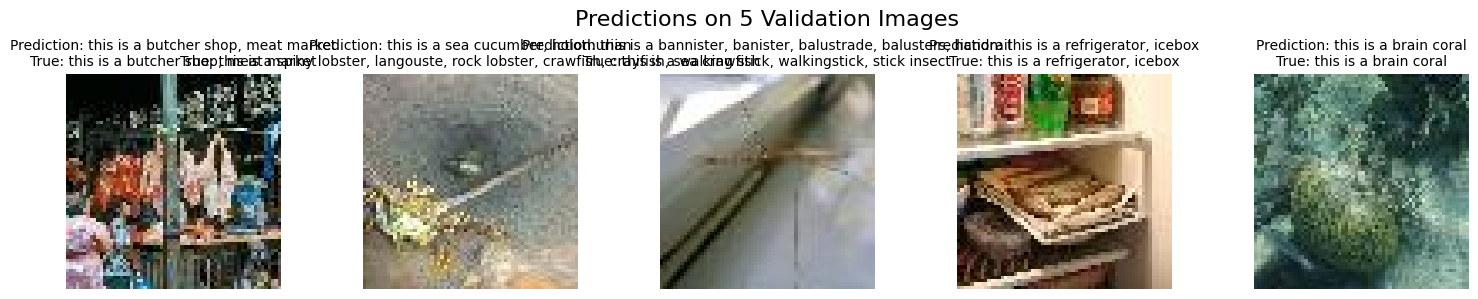


Predictions for 5 Validation Images:
Image 1: Prediction: this is a butcher shop, meat market, True: this is a butcher shop, meat market
Image 2: Prediction: this is a sea cucumber, holothurian, True: this is a spiny lobster, langouste, rock lobster, crawfish, crayfish, sea crawfish
Image 3: Prediction: this is a bannister, banister, balustrade, balusters, handrail, True: this is a walking stick, walkingstick, stick insect
Image 4: Prediction: this is a refrigerator, icebox, True: this is a refrigerator, icebox
Image 5: Prediction: this is a brain coral, True: this is a brain coral


In [17]:
import numpy as np


wnids_to_names = {}
with open(ROOT_DIR / 'words.txt', 'r') as f:
    for line in f:
        wnid, name = line.strip().split('\t')
        wnids_to_names[wnid] = name


net.load_state_dict(torch.load('best_model.pt'))
net.eval()


id2syn = {i: c for c, i in syn2id.items()}
id2name = {i: wnids_to_names[c] for c, i in syn2id.items()}


val_dataset = val_dl.dataset
num_images = 5
indices = np.random.choice(len(val_dataset), num_images, replace=False)


fig, axes = plt.subplots(1, num_images, figsize=(15, 3))
if num_images == 1:
    axes = [axes]


inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)


with torch.no_grad():
    for i, idx in enumerate(indices):

        image, true_label = val_dataset[idx]
        true_class_name = id2name[true_label]


        image_tensor = image.unsqueeze(0).to(device)


        logits = net(image_tensor)
        predicted_idx = logits.argmax(1).item()
        predicted_class_name = id2name[predicted_idx]


        image_display = inv_normalize(image).permute(1, 2, 0).cpu().numpy()
        image_display = np.clip(image_display, 0, 1)


        axes[i].imshow(image_display)
        axes[i].set_title(f"Prediction: this is a {predicted_class_name}\nTrue: this is a {true_class_name}", fontsize=10)
        axes[i].axis('off')

plt.suptitle("Predictions on 5 Validation Images", fontsize=16)
plt.tight_layout()
plt.show()


print("\nPredictions for 5 Validation Images:")
for i, idx in enumerate(indices):
    _, true_label = val_dataset[idx]
    image_tensor = val_dataset[idx][0].unsqueeze(0).to(device)
    logits = net(image_tensor)
    predicted_idx = logits.argmax(1).item()
    print(f"Image {i+1}: Prediction: this is a {id2name[predicted_idx]}, True: this is a {id2name[true_label]}")

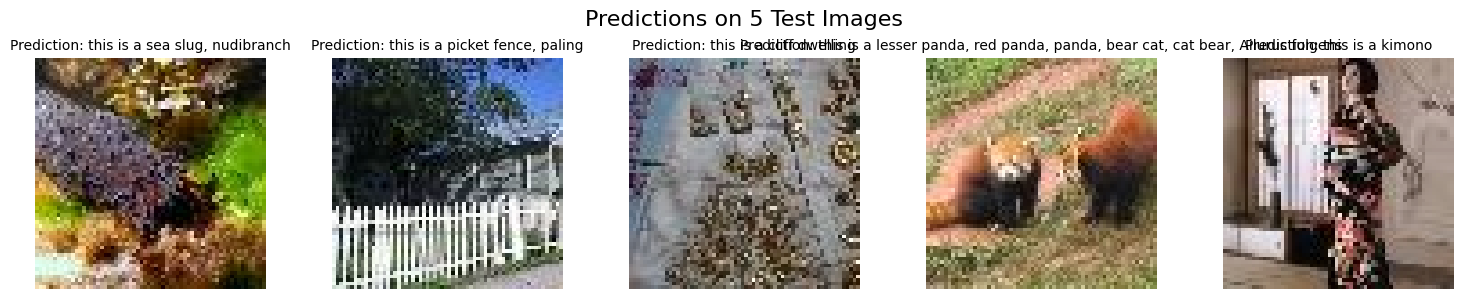


Predictions for 5 Test Images (True labels unavailable):
Image 1: Prediction: this is a sea slug, nudibranch
Image 2: Prediction: this is a picket fence, paling
Image 3: Prediction: this is a cliff dwelling
Image 4: Prediction: this is a lesser panda, red panda, panda, bear cat, cat bear, Ailurus fulgens
Image 5: Prediction: this is a kimono


In [22]:
wnids_to_names = {}
with open(ROOT_DIR / 'words.txt', 'r') as f:
    for line in f:
        wnid, name = line.strip().split('\t')
        wnids_to_names[wnid] = name


net.load_state_dict(torch.load('best_model.pt'))
net.eval()


id2syn = {i: c for c, i in syn2id.items()}
id2name = {i: wnids_to_names[c] for c, i in syn2id.items()}


test_tfms = transforms.Compose([transforms.ToTensor(), normalize])
test_dataset = TinyImageNet('test', test_tfms)
test_dl = DataLoader(test_dataset, batch_size=BATCHSIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)


test_dataset = test_dl.dataset
num_images = 5
indices = np.random.choice(len(test_dataset), num_images, replace=False)


fig, axes = plt.subplots(1, num_images, figsize=(15, 3))
if num_images == 1:
    axes = [axes]


inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)


with torch.no_grad():
    for i, idx in enumerate(indices):

        image, _ = test_dataset[idx]


        image_tensor = image.unsqueeze(0).to(device)


        logits = net(image_tensor)
        predicted_idx = logits.argmax(1).item()
        predicted_class_name = id2name[predicted_idx]


        image_display = inv_normalize(image).permute(1, 2, 0).cpu().numpy()
        image_display = np.clip(image_display, 0, 1)


        axes[i].imshow(image_display)
        axes[i].set_title(f"Prediction: this is a {predicted_class_name}", fontsize=10)
        axes[i].axis('off')

plt.suptitle("Predictions on 5 Test Images", fontsize=16)
plt.tight_layout()
plt.show()


print("\nPredictions for 5 Test Images (True labels unavailable):")
for i, idx in enumerate(indices):
    image, _ = test_dataset[idx]
    image_tensor = image.unsqueeze(0).to(device)
    logits = net(image_tensor)
    predicted_idx = logits.argmax(1).item()
    print(f"Image {i+1}: Prediction: this is a {id2name[predicted_idx]}")

In [ ]:
import ray
from ray import tune
from ray.tune.schedulers import ASHAScheduler
from ray.tune.search.optuna import OptunaSearch
import ray.train
import torch
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from pathlib import Path
import os


ROOT_DIR = Path('/content/tiny-imagenet-200')
TRAIN_DIR = ROOT_DIR / 'train'
VAL_DIR = ROOT_DIR / 'val'


train_transform = transforms.Compose([
    transforms.RandomCrop(64, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
train_dataset = TinyImageNet('train', train_transform)
val_dataset = TinyImageNet('val', val_transform)


num_workers = 2
train_dl = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=num_workers, pin_memory=torch.cuda.is_available())
val_dl = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=num_workers, pin_memory=torch.cuda.is_available())


def train_with_config(config, checkpoint_dir=None):
    device = 'cuda' if torch.cuda.is_available() else 'cpu'


    global ACTIVATION_FN, USE_BATCHNORM, USE_DROPOUT
    ACTIVATION_FN = config['activation_fn']
    USE_BATCHNORM = config['use_batchnorm']
    USE_DROPOUT = config['use_dropout']


    net = TinyResInceptionNet(
        n_cls=200,
        p_drop=config['drop_p'],
        depth=config['depth'],
        base_channels=config['base_channels']
    ).to(device)


    optimiser = optim.SGD(
        net.parameters(),
        lr=config['lr'],
        momentum=config['momentum'],
        weight_decay=config['weight_decay']
    )


    scheduler = None
    if config['use_scheduler']:
        scheduler = optim.lr_scheduler.MultiplicativeLR(
            optimiser,
            lr_lambda=lambda _: config['lr_decay_coeff']
        )


    if checkpoint_dir:
        checkpoint_path = Path(checkpoint_dir) / 'checkpoint'
        checkpoint = torch.load(checkpoint_path)
        net.load_state_dict(checkpoint['model_state_dict'])
        optimiser.load_state_dict(checkpoint['optimizer_state_dict'])
        if scheduler and 'scheduler_state_dict' in checkpoint and checkpoint['scheduler_state_dict']:
            scheduler.load_state_dict(checkpoint['scheduler_state_dict'])


    best_val_loss = float('inf')
    epochs_no_improve = 0
    for epoch in range(config['epochs']):
        tr = epoch_loop(net, train_dl, device, optimiser)
        va = epoch_loop(net, val_dl, device)

        if scheduler:
            scheduler.step()


        val_loss = va['loss']
        if config['use_early_stop']:
            if val_loss < best_val_loss - 1e-4:
                best_val_loss = val_loss
                epochs_no_improve = 0
            else:
                epochs_no_improve += 1
            if epochs_no_improve >= config['patience']:
                break


        if checkpoint_dir and epoch % 5 == 0:
            checkpoint_path = Path(checkpoint_dir) / 'checkpoint'
            torch.save({
                'model_state_dict': net.state_dict(),
                'optimizer_state_dict': optimiser.state_dict(),
                'scheduler_state_dict': scheduler.state_dict() if scheduler else None
            }, checkpoint_path)


        ray.train.report({
            'loss': va['loss'],
            'top1': va['top1'],
            'top5': va['top5'],
            'precision': va['precision'],
            'recall': va['recall'],
            'f1': va['f1']
        })


config = {
    'drop_p': tune.uniform(0, 0.5),
    'depth': tune.randint(1, 5),
    'base_channels': tune.choice([32, 64, 96, 128]),
    'lr': tune.loguniform(1e-4, 1e-2),
    'weight_decay': tune.loguniform(1e-4, 0.1),
    'momentum': tune.uniform(0.85, 0.95),
    'use_scheduler': tune.choice([True, False]),
    'lr_decay_coeff': tune.uniform(0.85, 0.95),
    'activation_fn': tune.choice(['relu', 'leaky_relu', 'elu', 'sigmoid', 'tanh']),
    'use_batchnorm': tune.choice([True, False]),
    'use_dropout': tune.choice([True, False]),
    'use_early_stop': tune.choice([True, False]),
    'patience': tune.choice([5]),
    'epochs': 10,
    'num_workers': 2
}


scheduler = ASHAScheduler(
    metric='loss',
    mode='min',
    max_t=config['epochs'],
    grace_period=3,
    reduction_factor=2
)
search = OptunaSearch(
    metric='loss',
    mode='min'
)


ray.shutdown()
ray.init(ignore_reinit_error=True)

analysis = tune.run(
    train_with_config,
    config=config,
    scheduler=scheduler,
    search_alg=search,
    num_samples=10,
    resources_per_trial={'cpu': 2, 'gpu': 1 if torch.cuda.is_available() else 0},
    name='tiny_res_inception_tune_user_defined',
    verbose=1
)

# Print best configuration
best_trial = analysis.best_trial
print("Best trial config:", best_trial.config)
print(f"Best trial validation loss: {best_trial.last_result['loss']:.4f}")
print(f"Best trial validation top-1 accuracy: {best_trial.last_result['top1']*100:.1f}%")
print(f"Best trial validation top-5: {best_trial.last_result['top5']*100:.1f}%")
print(f"Best trial precision: {best_trial.last_result['precision']*100:.1f}%")
print(f"Best trial recall: {best_trial.last_result['recall']*100:.1f}%")
print(f"Best trial F1: {best_trial.last_result['f1']*100:.1f}%")

2025-06-06 19:34:26,648	INFO worker.py:1888 -- Started a local Ray instance.
[I 2025-06-06 19:34:28,544] A new study created in memory with name: optuna


+-------------------------------------------------------------------------+
| Configuration for experiment     tiny_res_inception_tune_user_defined   |
+-------------------------------------------------------------------------+
| Search algorithm                 SearchGenerator                        |
| Scheduler                        AsyncHyperBandScheduler                |
| Number of trials                 10                                     |
+-------------------------------------------------------------------------+

View detailed results here: /root/ray_results/tiny_res_inception_tune_user_defined
To visualize your results with TensorBoard, run: `tensorboard --logdir /tmp/ray/session_2025-06-06_19-34-21_704697_71915/artifacts/2025-06-06_19-34-28/tiny_res_inception_tune_user_defined/driver_artifacts`

Trial status: 1 PENDING
Current time: 2025-06-06 19:34:30. Total running time: 2s
Logical resource usage: 0/2 CPUs, 0/1 GPUs (0.0/1.0 accelerator_type:T4)
+---------------------

 26%|██▌       | 404/1563 [00:22<00:53, 21.76it/s]



Trial status: 1 RUNNING | 1 PENDING
Current time: 2025-06-06 19:35:00. Total running time: 32s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
| Trial name                   status        drop_p     depth     base_channels           lr     weight_decay     momentum   use_scheduler       lr_decay_coeff   activation_fn     use_batchnorm     use_dropout     use_early_stop       patience |
+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
| train_with_config_6b944b9f   RUNNING    0.355788          1               128   0.00012

 62%|██████▏   | 973/1563 [00:52<00:26, 21.96it/s]


Trial status: 1 RUNNING | 1 PENDING
Current time: 2025-06-06 19:35:30. Total running time: 1min 2s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
| Trial name                   status        drop_p     depth     base_channels           lr     weight_decay     momentum   use_scheduler       lr_decay_coeff   activation_fn     use_batchnorm     use_dropout     use_early_stop       patience |
+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
| train_with_config_6b944b9f   RUNNING    0.355788          1               128   0.00

... (164 outputs left out)

Trial status: 2 TERMINATED | 1 RUNNING | 1 PENDING
Current time: 2025-06-06 20:15:35. Total running time: 41min 6s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
| Trial name                   status          drop_p     depth     base_channels           lr     weight_decay     momentum   use_scheduler       lr_decay_coeff   activation_fn     use_batchnorm     use_dropout     use_early_stop       patience     iter     total time (s)      loss     top1     top5     precision |
+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------

 81%|████████  | 1261/1563 [01:35<00:22, 13.69it/s]


Trial status: 2 TERMINATED | 1 RUNNING | 1 PENDING
Current time: 2025-06-06 20:16:05. Total running time: 41min 36s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
| Trial name                   status          drop_p     depth     base_channels           lr     weight_decay     momentum   use_scheduler       lr_decay_coeff   activation_fn     use_batchnorm     use_dropout     use_early_stop       patience     iter     total time (s)      loss     top1     top5     precision |
+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------

 69%|██████▉   | 108/157 [00:03<00:01, 28.43it/s]
